In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# 1. Load relevant tables
customers = pd.read_csv('/content/olist_customers_dataset.csv')
orders = pd.read_csv('/content/olist_orders_dataset.csv', on_bad_lines='skip')

In [8]:
customers.head(5)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [9]:
orders.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
# 2. Filter valid orders and merge customer_unique_id
orders = orders[orders['order_status'] == 'delivered'].copy()
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

df = orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='inner')

In [19]:
df.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_month,cohort_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,2018-07,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02


In [10]:
# 3. Define Purchase Month and Cohort Month
df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['cohort_month'] = df.groupby('customer_unique_id')['order_month'].transform('min')

In [12]:
# Filter for the 2017 acquisition window requested by the prompt
df_2017 = df[df['cohort_month'].dt.year == 2017].copy()

In [13]:
# 4. Calculate Cohort Index (Month 0, Month 1, Month 2, ...)
cohort_year = df_2017['cohort_month'].dt.year
cohort_mon = df_2017['cohort_month'].dt.month
order_year = df_2017['order_month'].dt.year
order_mon = df_2017['order_month'].dt.month

In [14]:
df_2017['cohort_index'] = (order_year - cohort_year) * 12 + (order_mon - cohort_mon)

In [15]:
# 5. Create Cohort Matrix
cohort_data = df_2017.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

In [16]:
# 6. Calculate Retention Rate
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0) * 100

In [17]:
cohort_size

,0
cohort_month,
2017-01,717.0
2017-02,1628.0
2017-03,2502.0
2017-04,2256.0
2017-05,3451.0
2017-06,3037.0
2017-07,3752.0
2017-08,4057.0
2017-09,4004.0


In [18]:
retention_matrix

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
cohort_month,,,,,,,,,,,,,,,,,,,
2017-01,100.0,0.278940,0.278940,0.139470,0.418410,0.139470,0.418410,0.139470,0.139470,NaN,0.418410,0.139470,0.697350,0.418410,0.139470,0.139470,0.278940,0.418410,0.13947
2017-02,100.0,0.184275,0.307125,0.122850,0.429975,0.122850,0.245700,0.184275,0.122850,0.184275,0.122850,0.307125,0.122850,0.184275,0.122850,0.061425,0.061425,0.184275,NaN
2017-03,100.0,0.439648,0.359712,0.399680,0.359712,0.159872,0.159872,0.319744,0.319744,0.079936,0.359712,0.119904,0.199840,0.119904,0.159872,0.239808,0.079936,0.119904,NaN
2017-04,100.0,0.620567,0.221631,0.177305,0.265957,0.265957,0.354610,0.310284,0.310284,0.177305,0.265957,0.088652,0.044326,0.044326,0.088652,0.088652,0.132979,NaN,NaN
2017-05,100.0,0.463634,0.463634,0.289771,0.289771,0.318748,0.405680,0.144886,0.260794,0.260794,0.260794,0.347725,0.231817,0.028977,0.173863,0.202840,NaN,NaN,NaN
2017-06,100.0,0.493908,0.395127,0.428054,0.296345,0.395127,0.362200,0.230491,0.131709,0.197563,0.296345,0.362200,0.164636,0.164636,0.230491,NaN,NaN,NaN,NaN
2017-07,100.0,0.533049,0.346482,0.239872,0.293177,0.213220,0.319829,0.106610,0.186567,0.266525,0.213220,0.293177,0.133262,0.239872,NaN,NaN,NaN,NaN,NaN
2017-08,100.0,0.690165,0.345083,0.271136,0.345083,0.517624,0.295785,0.271136,0.147893,0.147893,0.246488,0.197190,0.123244,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,100.0,0.699301,0.549451,0.274725,0.449550,0.224775,0.224775,0.249750,0.274725,0.174825,0.249750,0.074925,NaN,NaN,NaN,NaN,NaN,NaN,NaN


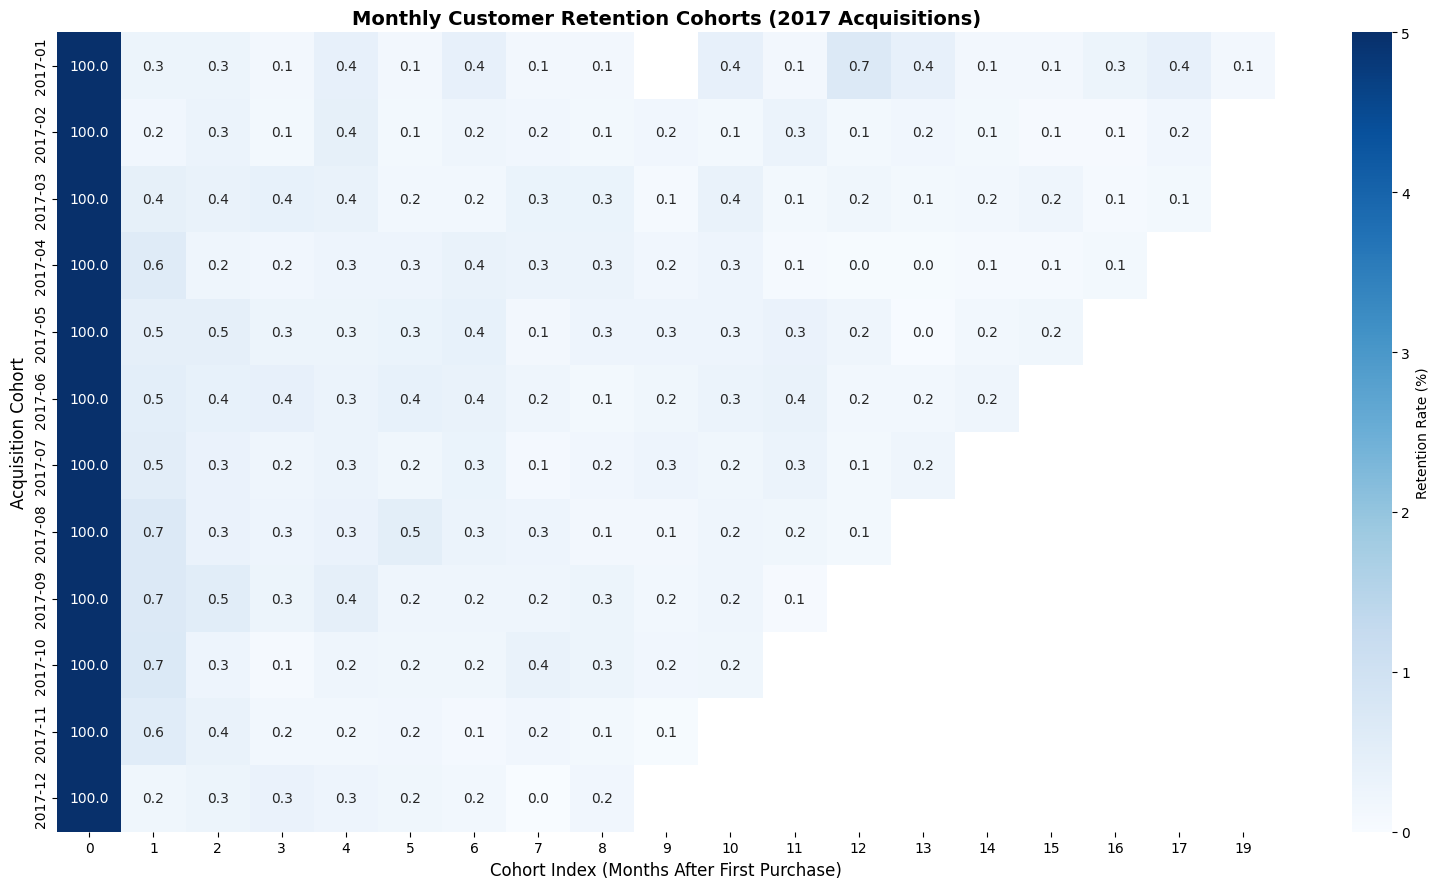

In [20]:
plt.figure(figsize=(16, 9))
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0.0,
    vmax=5.0, # Kept low because Olist repeat purchase rate is naturally under 3-5%
    cbar_kws={'label': 'Retention Rate (%)'}
)
plt.title('Monthly Customer Retention Cohorts (2017 Acquisitions)', fontsize=14, weight='bold')
plt.xlabel('Cohort Index (Months After First Purchase)', fontsize=12)
plt.ylabel('Acquisition Cohort', fontsize=12)
plt.tight_layout()
plt.savefig('cohort_retention_heatmap.png', dpi=300)
plt.show()

In [22]:
#Average Delivery Time per state correlated with Review Score.

from scipy import stats

# 1. Load reviews datasets
reviews = pd.read_csv('olist_order_reviews_dataset.csv')


# 2. Filter for delivered orders with valid delivery dates
orders = orders[orders['order_status'] == 'delivered'].dropna(
    subset=['order_purchase_timestamp', 'order_delivered_customer_date']
).copy()

# 3. Calculate delivery duration in days
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])

orders['delivery_time_days'] = (
    orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# Filter out edge case anomalies (e.g., negative duration or extreme outliers > 100 days)
orders = orders[(orders['delivery_time_days'] >= 0) & (orders['delivery_time_days'] <= 100)]

# 4. Merge Orders with Reviews and Customer State
# Average review score per order first (in case of multiple reviews per order)
order_reviews = reviews.groupby('order_id')['review_score'].mean().reset_index()

merged = orders.merge(order_reviews, on='order_id', how='inner')
merged = merged.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='inner')

# 5. Aggregate metrics at the State level
state_analysis = merged.groupby('customer_state').agg(
    total_orders=('order_id', 'count'),
    avg_delivery_time=('delivery_time_days', 'mean'),
    median_delivery_time=('delivery_time_days', 'median'),
    avg_review_score=('review_score', 'mean')
).reset_index()

# 6. Calculate Pearson and Spearman correlations
pearson_corr, p_value = stats.pearsonr(
    state_analysis['avg_delivery_time'],
    state_analysis['avg_review_score']
)
spearman_corr, sp_p_val = stats.spearmanr(
    state_analysis['avg_delivery_time'],
    state_analysis['avg_review_score']
)

print(f"State-Level Pearson Correlation: {pearson_corr:.4f} (p-value: {p_value:.4e})")
print(f"State-Level Spearman Correlation: {spearman_corr:.4f} (p-value: {sp_p_val:.4e})")
print("\nState Summary (Sorted by Longest Delivery Time):")
print(state_analysis.sort_values(by='avg_delivery_time', ascending=False).to_string(index=False))

State-Level Pearson Correlation: -0.4861 (p-value: 1.0150e-02)
State-Level Spearman Correlation: -0.4383 (p-value: 2.2194e-02)

State Summary (Sorted by Longest Delivery Time):
customer_state  total_orders  avg_delivery_time  median_delivery_time  avg_review_score
            RR            67          26.024803             25.007303          3.820896
            AM           250          25.461368             25.862309          4.284000
            AP           115          24.700689             24.094144          4.208696
            AL           665          24.661474             22.538993          3.843609
            PA          1585          23.492197             21.127141          3.915457
            AC           131          21.360405             18.333623          4.099237
            MA          1222          21.248493             19.131678          3.820376
            CE          2145          20.970469             18.140810          3.942191
            SE           553   